In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

In [ ]:
# !pip install pygwalker

In [ ]:
# import pandas as pd
# import pygwalker as pyg

In [ ]:
# [셀 1] 라이브러리 임포트 및 상수 정의
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ===코랩용 databench 데이터셋 위치===
# DATA = Path("/content/drive/Othercomputers/내 PC/dp4agent/data/bank_exp.parquet")

# ===코랩용 CardBase 데이터셋 위치===
# DATA = "/content/drive/Othercomputers/내 PC/dp4agent/data/CardBase.csv"        # 논문 속 데이터셋으로 변경

# ===로컬용 databench 데이터셋 위치===
DATA = Path("/content/drive/Othercomputers/내 PC/dp4agent/data/bank_exp.parquet")

# ===로컬용 CardBase 데이터셋 위치===
DATA = Path("data/CardBase.csv")
COL  = "Credit_Limit"

# ===클리핑 있을 때 Lower/Upper 바운드===
# L, U = 2000.0, 34000.0

# ===클리핑 없이 진행===
L, U = None, None
EPSILONS = [0.5, 0.75, 1.0, 1.25]

MAXQ      = 500           # 논문 방식이 쿼리를 최대 몇 번까지 반복하는지
REPS      = 50            # 반복 실험 횟수 (커버리지 추정용)

# ===95% 신뢰구간을 산정(ALPHA)했을 때, 그 '상대폭'이 0.01이하(THRESHOLD)로 5번 유지될 때(STREAK) 수렴으로 판단하고 정지===
ALPHA     = 0.05          # 1 - 0.95 신뢰수준 95%
THRESHOLD = 0.01          # 신뢰구간 상대폭이 1% 이하가 되면 정지
STREAK    = 5             # 위의 조건이 연속 5회 유지되어야 정지

# ===반복 실험을 위한 랜덤 함수===
rng = np.random.default_rng(0)

# ===결과는 /content/output에 생성===
Path("outputs").mkdir(exist_ok=True)

In [ ]:
# @title
# [셀 2] 데이터 로딩 및 민감도 계산

# ===databench 데이터셋===
# df = pd.read_parquet(DATA)

# ===KCI 논문 속 데이터셋===
df = pd.read_csv(DATA)

# ===COL  = "credit_limit"===
x  = df[COL].to_numpy(dtype=float)

n         = len(x)                  # 데이터 수: 500개
true_mean = x.mean()
clip_mean = true_mean
 
D_PAPER = x.max() - x.min() / n     # 논문 방식: 전역 (max - min)/n을 평균 질의에 대한 민감도로 설정

print("==논문과 민감도 비교==")
print(f"n(행 개수)         = {n}")
print(f"데이터 실제 평균값 = {true_mean:,.2f}")

print("======================")
print(f"최대: {x.max()}\t 최소:{x.min()}")
print(f"논문 속 민감도((최대-최소)/N)   = {D_PAPER:,.2f}")

==논문과 민감도 비교==
n(행 개수)         = 500
데이터 실제 평균값 = 252,614.00
최대: 899000.0	 최소:2000.0
논문 속 민감도((최대-최소)/N)   = 1,794.00


In [ ]:
# !pip install runcell

In [ ]:
# walker = pyg.walk(df)

In [ ]:
# @title
# [셀 3] 라플라스 노이즈를 붙인 질의 응답 테스트

# ===반복 실험을 위한 랜덤 함수===
# rng = np.random.default_rng(0) -> 위에서 이미 선언해둠

def stream(center, delta, eps, m, rng):
    """m번의 독립 질의. 질의마다 eps를 소모하고 라플라스 노이즈를 붙인 응답을 반환."""
    # m번을 한꺼번에 수행
    # 질의를 m번 던진 것과 수학적으로 동일하고, 순차 구성 정리에 따라 총 예산은 m·ε이 됨
    b = delta / eps                     # 라플라스 척도 파라미터

    # 분포 중앙이 0이고, 스케일 파라미터가 b(민감도/ε)인 라플라스 분포에서 m개의 샘플을 생성하고 반환
    return center + rng.laplace(loc=0.0, scale=b, size=m)

#
demo = stream(true_mean, D_PAPER, 1.0, 5, rng)

print(f"실제 평균값: {true_mean:,.2f}")

print("라플라스 스케일 파라미터(b): ", D_PAPER / 1.0)
print("\n== 예시 결과값 5개==")
example_5 = np.round(demo, 2)
for i in range(5):
  print(f"- {i+1}번째: {example_5[i]}")

실제 평균값: 252,614.00
라플라스 스케일 파라미터(b):  1794.0

== 예시 결과값 5개==
- 1번째: 253188.26
- 2번째: 251507.14
- 3번째: 248125.98
- 4번째: 246497.22
- 5번째: 254380.99


> 시각화 함수 `plot_track()`

In [ ]:
# @title
# [셀 5] 시각화 코드 함수로 감싼 형태
def plot_track(h, title="", true_mean=None, k_stop=None):
    if true_mean is None:
        true_mean = globals().get("true_mean", globals().get("TRUE"))

    # fig는 액자, ax는 실제 그림 그리는 도화지 
    fig, ax = plt.subplots(figsize=(11, 5))
    ok  = h[h.covered == True]
    bad = h[h.covered == False]

    # 데이터를 안정적인 것과 불안정한 것으로 나누어 시각화
    for g, c, lab in [(ok, "tab:blue", "Stable"), (bad, "tab:red", "Unstable")]:
        if len(g):
            # x축 = 샘플 개수(k)
            # y축 = 추정 평균(mean)
            # 오차막대 = 신뢰구간 반폭(moe)
            ax.errorbar(g.k, g["mean"], yerr=g.moe, 
                        fmt="o", ms=3, color=c,
                        ecolor=c, elinewidth=1.2, capsize=0, alpha=0.85, label=lab)

    # 기준선(실제 평균) 그리기
    ax.axhline(true_mean, ls="--", c="green", lw=1.2, label="True Mean")
    if k_stop is not None:
        ax.axvline(k_stop, ls="--", c="k", lw=1, label=f"Converged at {k_stop}")

    r = h.covered.mean()
    ax.set_title(f"{title} | Stable={r:.1%}, Unstable={1-r:.1%}")
    ax.set_xlabel("Query Count"); ax.set_ylabel(COL)
    ax.grid(alpha=0.3); ax.legend()
    plt.tight_layout(); plt.show()

> 실험 함수 `run_live()`

In [ ]:
# @title
# [셀 4-2] run_live() 함수 수정 -> 정지 조건 판단
from scipy import stats

def run_live(delta, eps, seed=0, threshold=THRESHOLD, streak_required=STREAK,
             maxq=MAXQ, verbose=True, verbose_upto=20, every=10):
    """질의를 1개씩 받아 누적 통계를 갱신하고, 정지 조건 충족 시 중단."""
    r = np.random.default_rng(seed)
    b = delta / eps

    s1 = s2 = 0.0          # Σx, Σx²
    streak = 0
    hist = []              # 시각화용 기록

    if verbose:
        print(f"delta={delta:,.4f}  eps={eps}  b={b:,.4f}  "
              f"threshold={threshold}  streak_required={streak_required}\n")

    for k in range(1, maxq + 1):
        v = true_mean + r.laplace(0.0, b)      # 질의 1회 = eps 소모
        s1 += v
        s2 += v * v

        mean = s1 / k
        if k < 2:
            moe = relw = lo = hi = np.nan # 아직 질의를 한 번 밖에 안 했다면, '신뢰구간'이 만들어지지 않음
            hit = False
        else:
            # 현재까지 수집한 데이터로 평균의 신뢰구간을 계산하고, 신뢰구간이 충분히 좁아졌는지 판단
            var  = max((s2 - k * mean**2) / (k - 1), 0.0)       # 분산
            se   = np.sqrt(var) / np.sqrt(k)                    # 표준 오차. 위에서 구한 분산 -> 표준편차로 바꾸고 루트 k로 나눠 구함
            moe  = stats.t.ppf(1 - ALPHA/2, df=k-1) * se        # moe는 Margin Of Error(오차한계) 신뢰구간: [mean-moe, mean+moe]
            lo, hi = mean - moe, mean + moe                     # 신뢰구간 하한/상한    
            relw = 2 * moe / abs(mean)
            hit  = relw < threshold

        # 신뢰구간 폭 안에 실제 평균(모평균)이 포함되는지 여부 확인
        # covered = (abs(mean - true_mean) <= moe) if np.isfinite(moe) else pd.NA
        if np.isfinite(moe):
            covered = (abs(mean - true_mean) <= moe)
        else:
            covered = pd.NA        
        resp_in = (lo <= v <= hi) if np.isfinite(moe) else pd.NA          # 추가

        streak = streak + 1 if hit else 0
        hist.append((k, v, mean, moe, lo, hi, relw, streak, covered, resp_in))   # resp_in 추가

        # 1~verbose_upto회는 매번, 이후로는 every 배수마다(또는 정지 시점에) 출력
        if verbose and (k <= verbose_upto or k % every == 0 or streak >= streak_required):
            flag = "*" * streak
            mark = "-- " if covered is pd.NA else ("IN " if covered else "OUT")
            ci   = ("         --  ~          -- " if not np.isfinite(moe)
                    else f"{lo:11.2f} ~ {hi:11.2f}")
            print(f"k={k:>4} | resp={v:11.2f} | mean={mean:10.2f} | "
                  f"CI=[{ci}] | moe={moe:9.2f} | relw={relw:8.5f} | "
                  f"{mark} | streak={streak} {flag}")

        if streak >= streak_required:
            if verbose:
                print(f"\n>>> 정지: k={k}, eps_total={eps*k:.2f}, "
                      f"추정={mean:,.2f}, width={moe:.2f}, "
                      f"CI=[{lo:,.2f} ~ {hi:,.2f}]")
            break
    else:
        if verbose:
            print(f"\n>>> {maxq}회 내 미수렴")

    df = pd.DataFrame(hist, columns=["k","resp","mean","moe",
                                     "ci_lo","ci_hi","relw","streak","covered","resp_in"])
    df["covered"] = df["covered"].astype("boolean")
    df["resp_in"] = df["resp_in"].astype("boolean")
    return df

In [12]:
# ===def run_live(delta, eps, seed=0, threshold=THRESHOLD, streak_required=STREAK, maxq=MAXQ, verbose=True, verbose_upto=15, every=10):===

# ===반복 실험을 하지 않기 때문에 seed는 무의미한 값===
# ===verbose_upto이후부터는 every마다 터미널 출력==
h = run_live(D_PAPER, 0.5, seed=0, threshold=0.01, streak_required=7, verbose_upto=15, every=10)

delta=1,794.0000  eps=0.5  b=3,588.0000  threshold=0.01  streak_required=7

k=   1 | resp=  253762.52 | mean= 253762.52 | CI=[         --  ~          -- ] | moe=      nan | relw=     nan | --  | streak=0 
k=   2 | resp=  250400.29 | mean= 252081.40 | CI=[  230720.82 ~   273441.99] | moe= 21360.59 | relw= 0.16947 | IN  | streak=0 
k=   3 | resp=  243637.96 | mean= 249266.92 | CI=[  236457.34 ~   262076.51] | moe= 12809.59 | relw= 0.10278 | IN  | streak=0 
k=   4 | resp=  240380.45 | mean= 247045.30 | CI=[  237305.11 ~   256785.49] | moe=  9740.19 | relw= 0.07885 | IN  | streak=0 
k=   5 | resp=  256147.99 | mean= 248865.84 | CI=[  240566.77 ~   257164.91] | moe=  8299.07 | relw= 0.06670 | IN  | streak=0 
k=   6 | resp=  258878.27 | mean= 250534.58 | CI=[  242934.54 ~   258134.62] | moe=  7600.04 | relw= 0.06067 | IN  | streak=0 
k=   7 | resp=  253474.66 | mean= 250954.59 | CI=[  244754.63 ~   257154.55] | moe=  6199.96 | relw= 0.04941 | IN  | streak=0 
k=   8 | resp=  254818.19 | mean=

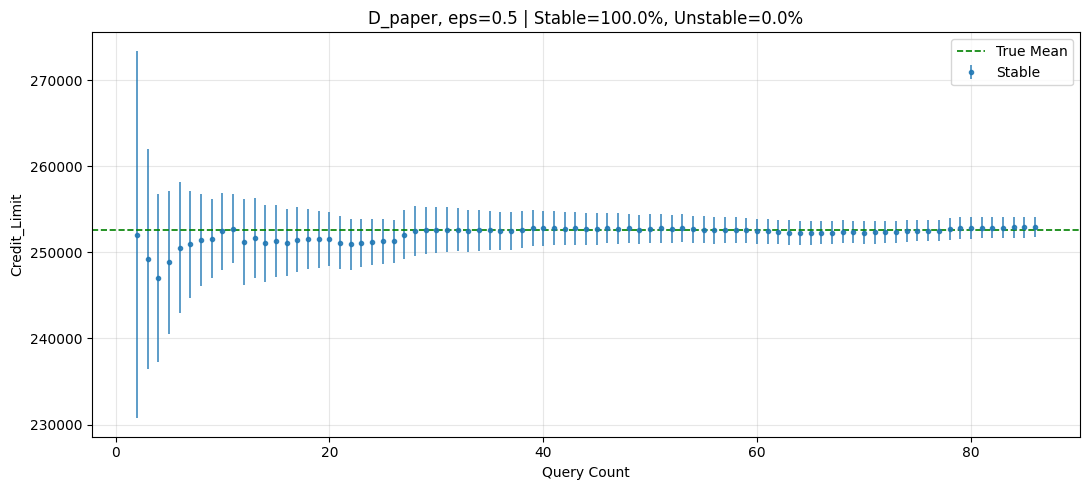

In [13]:
plot_track(h, title="D_paper, eps=0.5")

In [ ]:
# [셀 6] 조건 스윕 — 조건 재사용 버전
DELTAS     = {"D_paper": D_PAPER}
THRESHOLDS = [0.01, 0.03, 0.05, 0.1]
STREAKS    = [3, 5, 7, 10]

def find_stop(relw, threshold, streak_required):
    """상대폭이 threshold 미만으로 streak_required회 연속되면 그 질의 번호 반환."""
    streak = 0
    for i, w in enumerate(relw):                    # i=0 → k=1
        streak = streak + 1 if (np.isfinite(w) and w < threshold) else 0
        if streak >= streak_required:
            return i + 1
    return None


def sweep(deltas, epsilons=EPSILONS, thresholds=THRESHOLDS, streaks=STREAKS,
          reps=10, seed0=0, maxq=MAXQ, save=None):
    rows, raw = [], []

    for dname, delta in deltas.items():
        for eps in epsilons:
            # 궤적은 (delta, eps, seed)에만 의존 → 조합마다 다시 만들지 않는다.
            # threshold=0.0 이면 relw < 0.0 이 성립할 수 없어 조기 정지가 일어나지 않음.
            tracks = [run_live(delta, eps, seed=seed0 + i, threshold=0.0,
                               maxq=maxq, verbose=False)
                      for i in range(reps)]
            relws = [h.relw.to_numpy(dtype=float) for h in tracks]

            for th in thresholds:
                for st in streaks:
                    ks, covs = [], []
                    for i, (h, w) in enumerate(zip(tracks, relws)):
                        k = find_stop(w, th, st)
                        raw.append({"delta": dname, "eps": eps, "threshold": th,
                                    "streak": st, "seed": seed0 + i, "k": k})
                        if k is not None:
                            ks.append(k)
                            c = h.covered.iloc[k - 1]
                            covs.append(bool(c) if c is not pd.NA else np.nan)

                    rows.append({
                        "delta": dname, "eps": eps, "threshold": th, "streak": st,
                        "n_stop": len(ks),
                        "miss_rate": 1 - len(ks) / reps,
                        "k_mean": np.mean(ks) if ks else np.nan,
                        "k_std": np.std(ks, ddof=1) if len(ks) > 1 else np.nan,
                        "eps_total": eps * np.mean(ks) if ks else np.nan,
                        "cover_at_stop": np.nanmean(covs) if covs else np.nan,
                    })

    res = pd.DataFrame(rows)
    raw = pd.DataFrame(raw)
    if save:
        res.to_csv(save, index=False)
        # raw.to_csv(save.replace(".csv", "_raw.csv"), index=False)
    return res, raw

# miss_rate: 조건 조합에서 반복 시행 중 정지 조건을 만족하지 못한 시행의 비율
# cover_at_stop: 10번의 반복 시행 중 정지 시점의 신뢰구간이 참평균을 포함했는지에 대한 비율
# res.shape: 실험 후 만들어지는 요약 데이터프레임의 행/열 개수 (조건 조합 수 128, attributes 10)

In [ ]:
res, raw = sweep(DELTAS, reps=10, save="outputs/exp_result_0907_v1.csv")
print(res.shape, "| 시뮬레이션 횟수:", len(DELTAS) * len(EPSILONS) * 10)
# res.head(10)

(64, 10) | 시뮬레이션 횟수: 40
